In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load monthly ETF returns from Day 4
data_path = Path(
    "../data/processed/us_etf_monthly_returns_2008_2025.csv"
)

returns = pd.read_csv(
    data_path,
    parse_dates=["observation_date"],
    index_col="observation_date"
)

returns = returns.sort_index()

# Validate the dataset
assert returns.shape == (216, 3)
assert returns.index.is_unique
assert not returns.isna().any().any()

print("Dataset shape:", returns.shape)

print("\nDate range:")
print(returns.index.min())
print(returns.index.max())

print("\nAssets:", returns.columns.tolist())

print("\nDescriptive statistics:")
display(returns.describe().round(2))


Dataset shape: (216, 3)

Date range:
2008-01-01 00:00:00
2025-12-01 00:00:00

Assets: ['SPY', 'IEF', 'GLD']

Descriptive statistics:


,SPY,IEF,GLD
count,216.00,216.00,216.00
mean,0.97,0.27,0.85
std,4.52,1.95,4.90
min,-16.52,-4.73,-16.14
25%,-1.43,-0.88,-2.23
50%,1.60,0.19,0.43
75%,3.70,1.34,4.13
max,12.70,7.75,12.79


In [2]:

# Convert percentage returns to decimal returns
r = returns / 100

# Number of monthly observations
n_months = len(r)

# Compound annual growth rate (CAGR)
growth_factors = (1 + r).prod()

cagr = (
    growth_factors ** (12 / n_months) - 1
) * 100

# Annualized volatility
annual_volatility = (
    returns.std(ddof=1) * np.sqrt(12)
)

# Construct a financial performance table
performance_summary = pd.DataFrame({
    "CAGR (%)": cagr,
    "Annualized Volatility (%)": annual_volatility
})

print("Number of months:", n_months)

print("\nFinancial Performance Summary:")
display(performance_summary.round(2))

print("\nFinal value of $100 invested:")
display((growth_factors * 100).round(2))


Number of months: 216

Financial Performance Summary:


,CAGR (%),Annualized Volatility (%)
SPY,10.97,15.67
IEF,3.00,6.75
GLD,9.11,16.96



Final value of $100 invested:


SPY    651.34
IEF    170.32
GLD    480.61
dtype: float64

In [3]:

# Download the 3-month Treasury yield from FRED
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=GS3M"

risk_free = pd.read_csv(url)

print("Dataset shape:", risk_free.shape)
print("\nColumns:", risk_free.columns.tolist())

display(risk_free.head())
display(risk_free.tail())


Dataset shape: (541, 2)

Columns: ['observation_date', 'GS3M']


,observation_date,GS3M
0,1981-09-01,15.61
1,1981-10-01,14.23
2,1981-11-01,11.35
3,1981-12-01,11.32
4,1982-01-01,12.92


,observation_date,GS3M
536,2026-05-01,3.69
537,2026-06-01,3.81
538,2026-07-01,3.87
539,2026-08-01,3.88
540,2026-09-01,4.09


In [4]:

# Prepare the historical risk-free rate

risk_free["observation_date"] = pd.to_datetime(
    risk_free["observation_date"]
)

risk_free["GS3M"] = pd.to_numeric(
    risk_free["GS3M"],
    errors="coerce"
)

risk_free_clean = (
    risk_free
    .set_index("observation_date")
    .sort_index()
    .loc["2007-12-01":"2025-12-01"]
    .copy()
)

print("Shape:", risk_free_clean.shape)

print("\nDate range:")
print(risk_free_clean.index.min())
print(risk_free_clean.index.max())

print("\nMissing values:")
print(risk_free_clean.isna().sum())

print("\nDuplicate dates:",
      risk_free_clean.index.duplicated().sum())

display(risk_free_clean.head())
display(risk_free_clean.tail())


Shape: (217, 1)

Date range:
2007-12-01 00:00:00
2025-12-01 00:00:00

Missing values:
GS3M    0
dtype: int64

Duplicate dates: 0


,GS3M
observation_date,
2007-12-01,3.07
2008-01-01,2.82
2008-02-01,2.17
2008-03-01,1.28
2008-04-01,1.31


,GS3M
observation_date,
2025-08-01,4.30
2025-09-01,4.07
2025-10-01,3.98
2025-11-01,3.94
2025-12-01,3.68


In [5]:

# Convert annualized Treasury yield to approximate monthly rate (%)
monthly_rf = risk_free_clean["GS3M"].shift(1) / 12

# Align risk-free data with ETF returns
monthly_rf = monthly_rf.reindex(returns.index)

# Validate
assert monthly_rf.notna().all()
assert monthly_rf.index.equals(returns.index)

# Calculate monthly excess returns (percentage points)
excess_returns = returns.sub(monthly_rf, axis=0)

# Annualized historical Sharpe ratios
sharpe_ratios = (
    excess_returns.mean()
    / excess_returns.std(ddof=1)
) * np.sqrt(12)

# Add results to our existing performance summary
performance_summary["Sharpe Ratio"] = sharpe_ratios

print("First monthly risk-free rate (%):")
print(round(monthly_rf.iloc[0], 4))

print("\nAnnualized Financial Performance:")
display(performance_summary.round(3))

print("\nMissing excess returns:")
print(excess_returns.isna().sum())


First monthly risk-free rate (%):
0.2558

Annualized Financial Performance:


,CAGR (%),Annualized Volatility (%),Sharpe Ratio
SPY,10.972,15.674,0.659
IEF,3.003,6.755,0.271
GLD,9.113,16.965,0.522



Missing excess returns:
SPY    0
IEF    0
GLD    0
dtype: int64


In [6]:

# Step 1: Reconstruct investment wealth from monthly returns
wealth_index = (
    (1 + returns / 100).cumprod() * 100
)

# Include the initial $100 investment in December 2007
initial_wealth = pd.DataFrame(
    100.0,
    index=pd.DatetimeIndex(["2007-12-01"]),
    columns=returns.columns
)

wealth_index = pd.concat(
    [initial_wealth, wealth_index]
).sort_index()

# Step 2: Calculate historical running peaks
running_peak = wealth_index.cummax()

# Step 3: Calculate drawdown from each previous peak
drawdown = (
    wealth_index / running_peak - 1
) * 100

# Step 4: Identify maximum drawdowns
max_drawdown = drawdown.min()

max_drawdown_dates = drawdown.idxmin()

# Add results to our financial performance summary
performance_summary["Max Drawdown (%)"] = max_drawdown

print("Updated Financial Performance Summary:")
display(performance_summary.round(2))

print("\nDates of Maximum Drawdown:")
display(max_drawdown_dates)

print("\nMissing values:")
print(drawdown.isna().sum())


Updated Financial Performance Summary:


,CAGR (%),Annualized Volatility (%),Sharpe Ratio,Max Drawdown (%)
SPY,10.97,15.67,0.66,-48.22
IEF,3.00,6.75,0.27,-23.15
GLD,9.11,16.96,0.52,-42.91



Dates of Maximum Drawdown:


SPY   2009-02-01
IEF   2023-10-01
GLD   2015-12-01
dtype: datetime64[ns]


Missing values:
SPY    0
IEF    0
GLD    0
dtype: int64


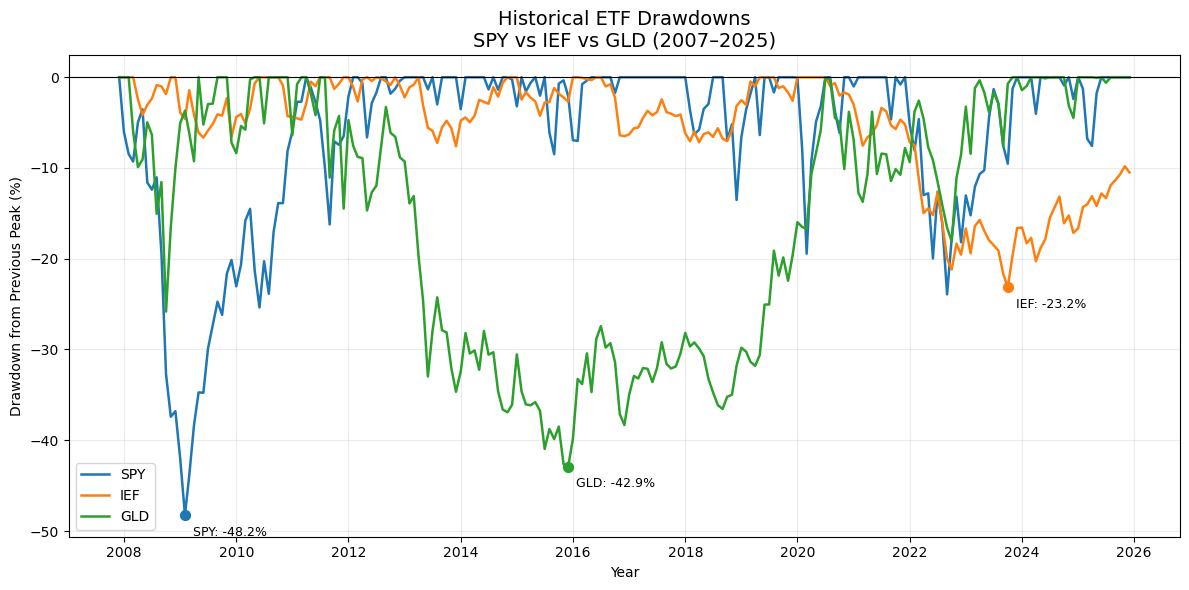

In [7]:

import matplotlib.pyplot as plt
from pathlib import Path

fig, ax = plt.subplots(figsize=(12, 6))

for ticker in ["SPY", "IEF", "GLD"]:

    # Draw the historical drawdown series
    ax.plot(
        drawdown.index,
        drawdown[ticker],
        label=ticker,
        linewidth=1.8
    )

    # Identify the maximum drawdown point
    trough_date = drawdown[ticker].idxmin()
    trough_value = drawdown.loc[trough_date, ticker]

    ax.scatter(
        trough_date,
        trough_value,
        s=50,
        zorder=5
    )

    ax.annotate(
        f"{ticker}: {trough_value:.1f}%",
        xy=(trough_date, trough_value),
        xytext=(6, -15),
        textcoords="offset points",
        fontsize=9
    )

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title(
    "Historical ETF Drawdowns\n"
    "SPY vs IEF vs GLD (2007–2025)",
    fontsize=14
)

ax.set_xlabel("Year")
ax.set_ylabel("Drawdown from Previous Peak (%)")

ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "etf_historical_drawdowns.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [8]:

# Correlation Analysis: ETF Monthly Returns

# Calculate Pearson correlation matrix
asset_correlations = returns.corr(method="pearson")

print("Monthly ETF Return Correlations (2008–2025)")
display(asset_correlations.round(3))

# Verify the correlation matrix
assert asset_correlations.shape == (3, 3)

assert np.allclose(
    np.diag(asset_correlations),
    1.0
)

assert np.allclose(
    asset_correlations,
    asset_correlations.T
)

print("\nCORRELATION MATRIX VALIDATION: PASSED")


Monthly ETF Return Correlations (2008–2025)


,SPY,IEF,GLD
SPY,1.000,-0.061,0.072
IEF,-0.061,1.000,0.355
GLD,0.072,0.355,1.000



CORRELATION MATRIX VALIDATION: PASSED


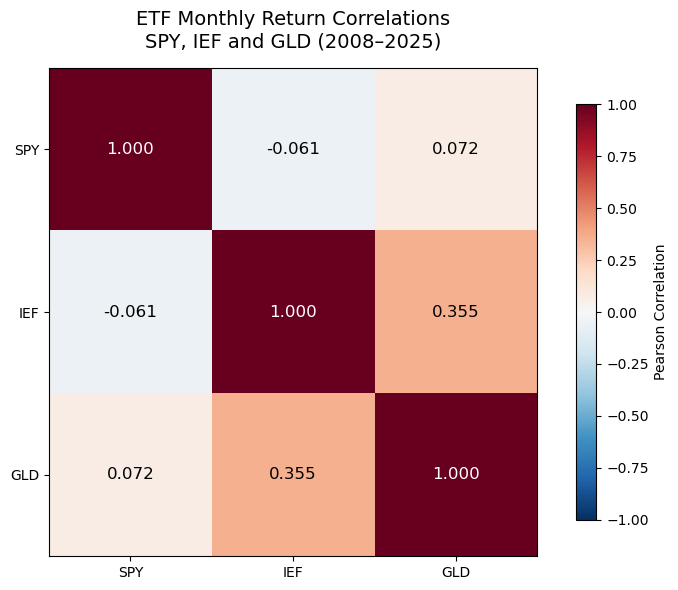

In [9]:

# ETF Monthly Return Correlation Heatmap

fig, ax = plt.subplots(figsize=(8, 6))

heatmap = ax.imshow(
    asset_correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

assets = asset_correlations.columns.tolist()

ax.set_xticks(range(len(assets)))
ax.set_yticks(range(len(assets)))

ax.set_xticklabels(assets)
ax.set_yticklabels(assets)

# Add correlation values inside each cell
for i in range(len(assets)):
    for j in range(len(assets)):
        value = asset_correlations.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=12,
            color="white" if abs(value) > 0.7 else "black"
        )

ax.set_title(
    "ETF Monthly Return Correlations\n"
    "SPY, IEF and GLD (2008–2025)",
    fontsize=14,
    pad=15
)

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    shrink=0.85
)

colorbar.set_label("Pearson Correlation")

fig.tight_layout()

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "etf_return_correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [10]:

# Correlation Stability Across Historical Periods

periods = {
    "2008-2013": ("2008-01-01", "2013-12-01"),
    "2014-2019": ("2014-01-01", "2019-12-01"),
    "2020-2025": ("2020-01-01", "2025-12-01")
}

correlation_results = []

for period_name, (start, end) in periods.items():

    period_returns = returns.loc[start:end]

    # Each period should contain exactly 72 months
    assert len(period_returns) == 72

    corr = period_returns.corr()

    correlation_results.append({
        "Period": period_name,
        "Observations": len(period_returns),
        "SPY-IEF": corr.loc["SPY", "IEF"],
        "SPY-GLD": corr.loc["SPY", "GLD"],
        "IEF-GLD": corr.loc["IEF", "GLD"]
    })

period_correlations = pd.DataFrame(
    correlation_results
).set_index("Period")

print("Asset Correlations Across Historical Periods")
display(period_correlations.round(3))


Asset Correlations Across Historical Periods


,Observations,SPY-IEF,SPY-GLD,IEF-GLD
Period,,,,
2008-2013,72,-0.282,0.074,0.301
2014-2019,72,-0.338,-0.124,0.530
2020-2025,72,0.312,0.182,0.367


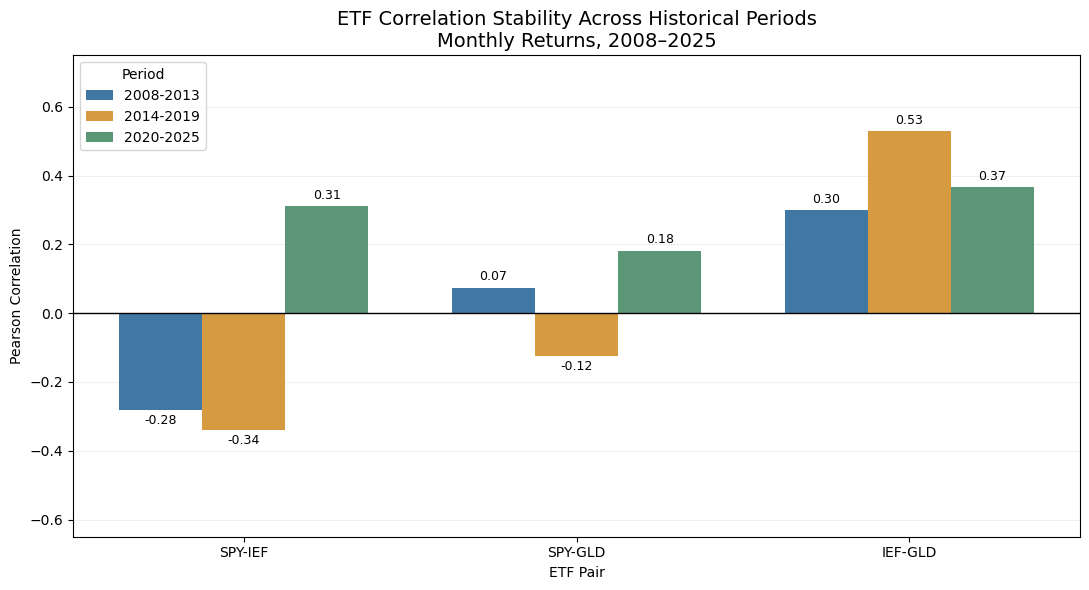

In [11]:

# Compare ETF correlations across historical periods

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pairs = ["SPY-IEF", "SPY-GLD", "IEF-GLD"]
x = np.arange(len(pairs))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

colors = ["#4078A3", "#D69B41", "#5B9676"]

for i, (period, row) in enumerate(
    period_correlations.iterrows()
):
    values = row[pairs].astype(float)

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=period,
        color=colors[i]
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

ax.axhline(0, color="black", linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(pairs)

ax.set_ylim(-0.65, 0.75)

ax.set_ylabel("Pearson Correlation")
ax.set_xlabel("ETF Pair")

ax.set_title(
    "ETF Correlation Stability Across Historical Periods\n"
    "Monthly Returns, 2008–2025",
    fontsize=14
)

ax.legend(title="Period")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "etf_correlation_stability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [12]:

from pathlib import Path

# Define output directories
processed_dir = Path("../data/processed")
tables_dir = Path("../reports/tables")

processed_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Validate results before saving
assert risk_free_clean.shape == (217, 1)
assert performance_summary.shape == (3, 4)
assert period_correlations.shape == (3, 4)

# Save the Treasury yield reference series
risk_free_clean.to_csv(
    processed_dir / "us_3m_treasury_yield_2007_2025.csv",
    index_label="observation_date"
)

# Save final ETF risk and performance metrics
performance_summary.to_csv(
    tables_dir / "etf_risk_performance_2008_2025.csv",
    index_label="ETF"
)

# Save correlations across historical periods
period_correlations.to_csv(
    tables_dir / "etf_period_correlations_2008_2025.csv",
    index_label="Period"
)

print("All Day 5 results saved successfully.")

print("\nPerformance summary:")
display(performance_summary.round(3))

print("\nHistorical correlations:")
display(period_correlations.round(3))


All Day 5 results saved successfully.

Performance summary:


,CAGR (%),Annualized Volatility (%),Sharpe Ratio,Max Drawdown (%)
SPY,10.972,15.674,0.659,-48.219
IEF,3.003,6.755,0.271,-23.153
GLD,9.113,16.965,0.522,-42.910



Historical correlations:


,Observations,SPY-IEF,SPY-GLD,IEF-GLD
Period,,,,
2008-2013,72,-0.282,0.074,0.301
2014-2019,72,-0.338,-0.124,0.530
2020-2025,72,0.312,0.182,0.367



## Key Findings and Economic Interpretation

### 1. Historical Risk and Return Performance

This analysis evaluates the historical risk and return characteristics of SPY, IEF, and GLD using 216 monthly observations from January 2008 through December 2025.

SPY achieved the highest compound annual growth rate (10.97%), followed by GLD (9.11%) and IEF (3.00%).

IEF exhibited the lowest annualized volatility (6.75%), while GLD had the highest (16.96%).

### 2. Risk-Adjusted Returns

The annualized historical Sharpe ratios were:

- SPY: 0.659
- GLD: 0.522
- IEF: 0.271

SPY delivered the highest average excess return relative to the variability of excess returns during the sample period.

The Sharpe ratios were estimated using monthly excess returns over an approximate risk-free benchmark derived from lagged three-month US Treasury yields.

These results describe historical performance and do not establish future investment superiority.

### 3. Maximum Drawdown

Maximum drawdowns based on monthly closing values were:

- SPY: -48.22%, February 2009
- IEF: -23.15%, October 2023
- GLD: -42.91%, December 2015

Although SPY achieved the strongest historical risk-adjusted performance according to the Sharpe ratio, it also experienced the largest peak-to-trough loss.

The three assets reached their maximum drawdowns in different historical periods, highlighting differences in their risk profiles.

### 4. Asset Return Correlations

Full-sample Pearson correlations between monthly ETF returns were:

- SPY–IEF: -0.061
- SPY–GLD: +0.072
- IEF–GLD: +0.355

The relatively low correlations between SPY and the other two ETFs suggest potential diversification benefits.

However, correlation alone does not establish how much portfolio risk would be reduced.

### 5. Correlation Stability Across Historical Periods

The SPY–IEF correlation changed across three six-year periods:

- 2008–2013: -0.282
- 2014–2019: -0.338
- 2020–2025: +0.312

The change from negative to positive correlation suggests that the historical stock-bond relationship was not constant across the examined periods.

This finding raises questions about the reliability of stock-bond diversification under changing market conditions.

However, the periods are chronological subsamples rather than formally identified macroeconomic regimes. Their differences do not establish that inflation or monetary policy caused the observed correlation changes.

## Methodological Limitations

- The analysis is historical and does not predict future returns.
- Standard deviation captures variability but does not fully describe investment risk.
- Annualized volatility and Sharpe ratios rely on conventional scaling assumptions that may be affected by serial dependence.
- The three-month Treasury yield is an approximate risk-free benchmark, not an exact realized one-month risk-free return.
- Maximum drawdowns were calculated using monthly closing values and may underestimate intramonth losses.
- Correlations are descriptive and may change across economic conditions.
- Differences in subsample correlations have not yet been formally tested for statistical significance.
- The analysis does not account for investor-specific fees, taxes, or currency conversion.
- No causal effects of macroeconomic variables on asset returns have been established.

## Implications for Further Analysis

The results suggest that assessing individual asset performance is insufficient for understanding portfolio diversification.

The next phase will investigate whether macroeconomic conditions, including inflation and monetary policy, are associated with differences in asset performance and cross-asset correlations.

This will help establish whether historical macroeconomic regimes contain useful information for portfolio risk management.
